# 02 - Locked research: the stronger baseline stays visible

**The calls-to-TEU benchmark beat the geography-aware model; the gain over aggregate shipping was uncertain.** This notebook reads the immutable 2024-2025 predictions and imports package evaluation functions. It does not train, select hyperparameters, change source lags or reacquire any data.

Current-vintage pseudo-real-time is not verified point-in-time. No historical first-release archive or prospective forecast performance is claimed. The independently coded arithmetic checker is separate from this package replay.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def sha(relative):
    return hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
import math
from scsi.research.pipeline import verify_lock
from scsi.research.evaluation import metrics
from scsi.research.bootstrap import paired_bootstrap
lock = verify_lock(ROOT)
results = read_json("artifacts/metrics/locked_results.json")
assert sha("artifacts/protocol_lock.json") == results["protocol_sha256"]
primary = next(e for e in results["experiments"] if e["role"] == "primary")
assert sha(primary["prediction_artifact"]) == primary["prediction_sha256"]
records = read_json(primary["prediction_artifact"])
frame = pd.DataFrame(records)
display(pd.DataFrame([{k: results[k] for k in ("claim_status", "n_independent_test_months", "total_prediction_records", "reporting_lag_robustness_undermines")}]))
print("Primary selected benchmark:", primary["selected_benchmark"])


,claim_status,n_independent_test_months,total_prediction_records,reporting_lag_robustness_undermines
0,PROMISING_BUT_UNCERTAIN,24,1080,True


Primary selected benchmark: simple_calls_to_teu


## Same months, same fallback, explicit units

WAPE is total absolute TEU error divided by total actual TEUs. MAE, RMSE and bias are in TEUs; bias is forecast minus actual. Direction compares forecast and actual year-over-year changes, so a flat seasonal forecast does not receive credit for predicting a nonzero change. There are 24 monthly outcomes, not 120 independent outcomes from five models.

In [2]:
replayed = []
for saved in primary["metrics"]:
    calculated = metrics(frame.loc[frame.model_id.eq(saved["model_id"])].to_dict("records"))
    assert all(math.isclose(calculated[k], saved[k], rel_tol=1e-12, abs_tol=1e-8) for k in calculated)
    replayed.append({"model_id": saved["model_id"], **calculated})
display(pd.DataFrame(replayed)[["model_id", "n_months", "wape", "mae", "rmse", "bias", "direction_accuracy", "fallback_rate"]])
display(frame.loc[frame.model_id.eq("geography_ridge") & frame.fallback_used, ["target_month", "fallback_reason", "prediction_teu", "actual_teu"]])


,model_id,n_months,wape,mae,rmse,bias,direction_accuracy,fallback_rate
0,seasonal_naive,24,0.112260,162176.962500,185903.740820,-115338.133333,0.000000,0.125
1,released_target_ridge,24,0.089193,128851.942608,164546.922553,-9778.011413,0.666667,0.125
2,aggregate_activity_ridge,24,0.118893,171758.954735,197699.903705,74874.449569,0.625000,0.125
3,geography_ridge,24,0.112134,161993.793689,182841.430806,90025.975118,0.791667,0.125
4,simple_calls_to_teu,24,0.073427,106076.767227,127722.955566,-46478.841373,0.666667,0.125


,target_month,fallback_reason,prediction_teu,actual_teu
3,2024-01,incomplete_current_or_prior_year_window,1170219.00,1328971.00
8,2024-02,incomplete_current_or_prior_year_window,976880.45,1289852.00
63,2025-01,incomplete_current_or_prior_year_window,1328971.00,1540517.25


## Paired calendar-block uncertainty

The same resampled calendar months are used for both models. Blocks do not wrap from December 2025 to January 2024, and missing target months are not compressed out of the calendar. Intervals describe comparative error, not a future monthly prediction band. Both block lengths and the seed were frozen.

In [3]:
wide = frame.pivot(index="target_month", columns="model_id", values="prediction_teu")
wide["actual_teu"] = frame.drop_duplicates("target_month").set_index("target_month").actual_teu
checks = []
for comparison in primary["comparisons"]:
    for saved in comparison["bootstrap"]:
        calculated = paired_bootstrap(wide, "geography_ridge", comparison["comparator"], saved["block_months"], 10000, 20261015)
        assert calculated == saved
        checks.append({"comparator": comparison["comparator"], "relative_lift": comparison["relative_lift"], **calculated})
display(pd.DataFrame(checks)[["comparator", "relative_lift", "block_months", "replicates", "lower", "upper", "calendar_months"]])


,comparator,relative_lift,block_months,replicates,lower,upper,calendar_months
0,aggregate_activity_ridge,0.056854,3,10000,-0.232755,0.309339,24
1,aggregate_activity_ridge,0.056854,6,10000,-0.281782,0.252207,24
2,simple_calls_to_teu,-0.527137,3,10000,-1.178711,-0.210090,24
3,simple_calls_to_teu,-0.527137,6,10000,-1.154192,-0.370156,24


## Actual locked-result figures

The figures below were generated from the same saved predictions. A geographic improvement over aggregate activity cannot erase the stronger noncandidate baseline. Full-policy error includes the shared seasonal fallback.

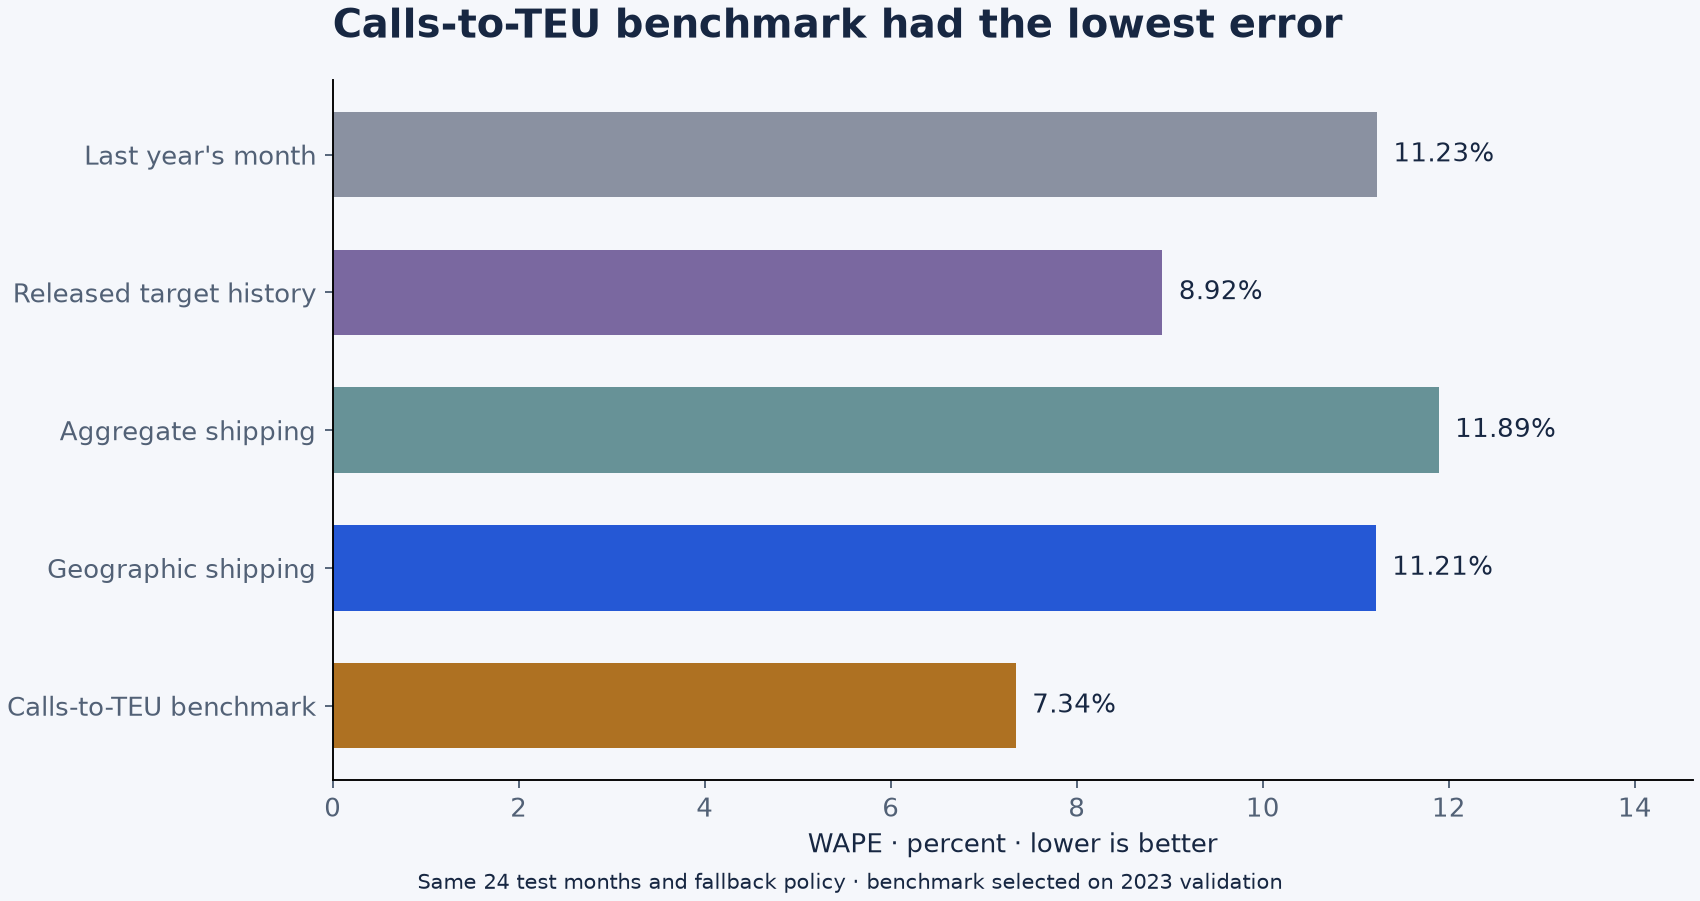

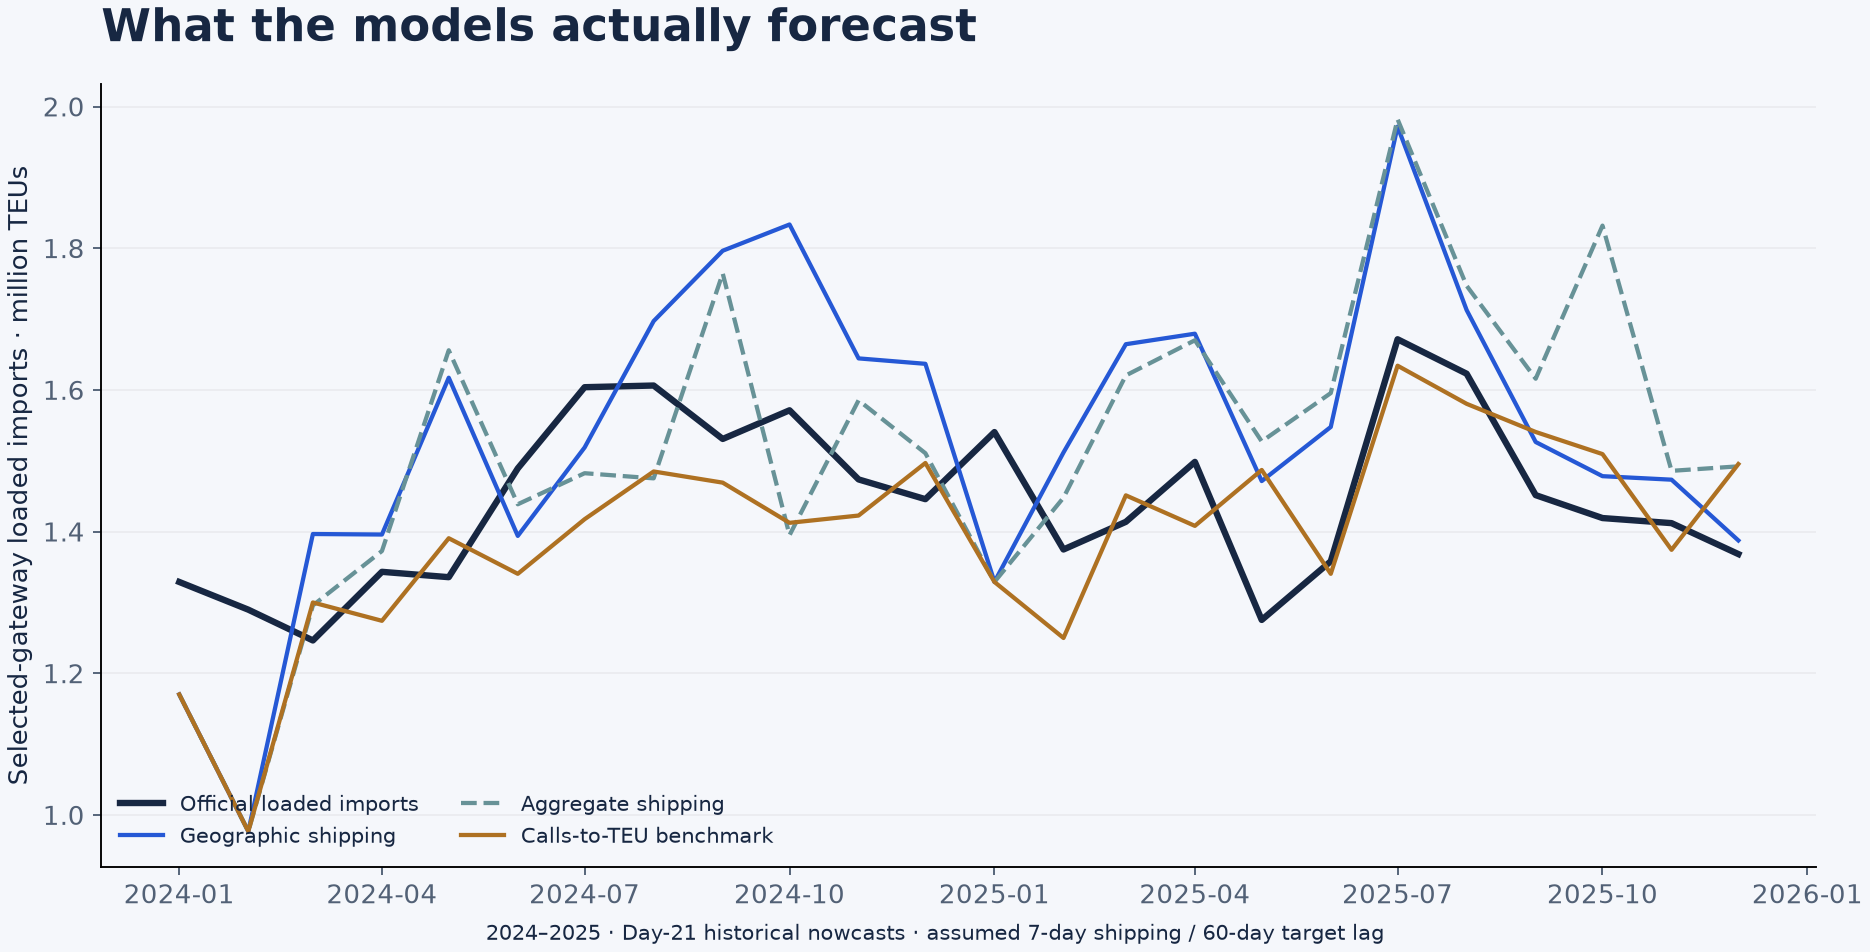

In [4]:
display(Image(filename=str(ROOT / "artifacts/figures/benchmark_comparison.png"), width=950))
display(Image(filename=str(ROOT / "artifacts/figures/actual_vs_predicted.png"), width=950))


## Availability assumptions and changed targets

Shipping lags are 7/14/28 days; assumed target-release lags are 60/90 days. Those are not verified historical publication timestamps. Leave-one-gateway-out experiments explicitly change the target; they are not replacements for an unfavorable primary comparison.

,experiment,role,geography_wape,aggregate_wape,selected_benchmark,baseline_wape
0,lag7_release60,primary,0.112134,0.118893,simple_calls_to_teu,0.073427
1,lag7_release90,reporting_lag_sensitivity,0.113424,0.123691,simple_calls_to_teu,0.072966
2,lag14_release60,reporting_lag_sensitivity,0.100002,0.090717,simple_calls_to_teu,0.062532
3,lag14_release90,reporting_lag_sensitivity,0.105180,0.092635,simple_calls_to_teu,0.062910
4,lag28_release60,reporting_lag_sensitivity,0.103614,0.100389,simple_calls_to_teu,0.078088
5,lag28_release90,reporting_lag_sensitivity,0.111190,0.093334,simple_calls_to_teu,0.079249
6,leave_out_san_pedro_bay,changed_target_gateway_exclusion,0.079275,0.075771,released_target_ridge,0.063123
7,leave_out_new_york_new_jersey,changed_target_gateway_exclusion,0.120155,0.110813,simple_calls_to_teu,0.082856
8,leave_out_savannah,changed_target_gateway_exclusion,0.111883,0.141739,simple_calls_to_teu,0.080004


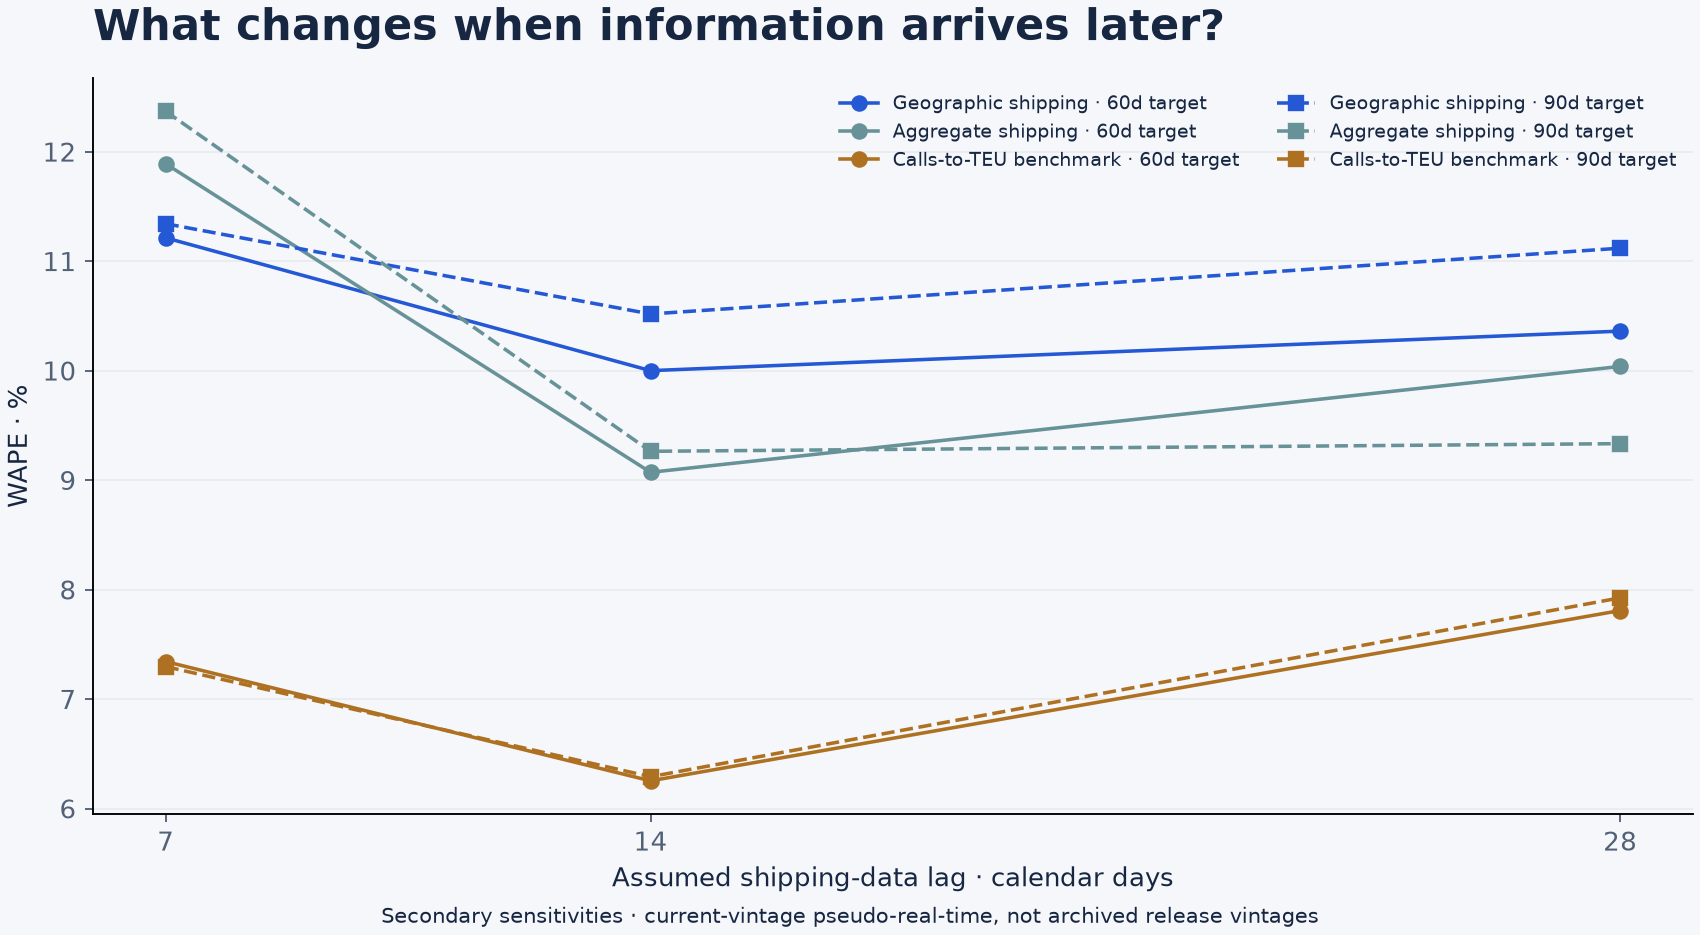

In [5]:
rows = []
for experiment in results["experiments"]:
    by_model = {m["model_id"]: m for m in experiment["metrics"]}
    rows.append({"experiment": experiment["experiment_id"], "role": experiment["role"], "geography_wape": by_model["geography_ridge"]["wape"], "aggregate_wape": by_model["aggregate_activity_ridge"]["wape"], "selected_benchmark": experiment["selected_benchmark"], "baseline_wape": by_model[experiment["selected_benchmark"]]["wape"]})
display(pd.DataFrame(rows))
display(Image(filename=str(ROOT / "artifacts/figures/availability_sensitivity.png"), width=950))


## Separate arithmetic audit and information-time limits

The checker independently recalculates metrics and the primary bootstrap with scalar loops, rather than calling the package evaluation functions used above. It checks serialized information clocks and coefficients, not the truth of the provider's historical data. Agent-assisted checks are not independent human validation.

In [6]:
audit = read_json("artifacts/audit/independent_research_audit.json")
assert audit["protocol_sha256"] == results["protocol_sha256"]
assert audit["locked_results_sha256"] == sha("artifacts/metrics/locked_results.json")
display(pd.DataFrame([{k: audit[k] for k in ("status", "prediction_records_checked", "training_month_release_checks", "serialized_ridge_predictions_reconstructed", "maximum_ridge_prediction_difference_teu", "independent_claim_status")}]))
for limitation in audit["limitations"]:
    print("-", limitation)
print("PortWatch attribution: Sources: Kpler; UN Global Platform; IMF PortWatch - https://portwatch.imf.org/")


,status,prediction_records_checked,training_month_release_checks,serialized_ridge_predictions_reconstructed,maximum_ridge_prediction_difference_teu,independent_claim_status
0,passed,1080,50865,579,4.656613e-10,PROMISING_BUT_UNCERTAIN


- No historical first-release snapshots: release lags are assumptions, not proof of historical availability.
- July 2026 PortWatch revisions affect the current-vintage 2019-2025 reconstruction.
- Only 24 test months; 1080 forecasts across overlapping experiments are not 1080 independent observations.
- NOAA 2024 cargo-proxy measurements are separate descriptive evidence, never a forecast regressor.
- Temporal receipts and coefficient reconstruction do not independently re-train or certify every source observation.
- Historical market knowledge and measurement-pilot exposure mean this is not globally unseen or prospective research.
PortWatch attribution: Sources: Kpler; UN Global Platform; IMF PortWatch - https://portwatch.imf.org/
